<a href="https://colab.research.google.com/github/Premraju5/Premraju5/blob/main/ImageClusturingProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install -q tensorflow scikit-learn pillow matplotlib
from google.colab import files

uploaded = files.upload()

Saving cat1.jpg to cat1.jpg
Saving cat2.jpg to cat2.jpg
Saving cat3.jpg to cat3.jpg
Saving cat4.jpg to cat4.jpg
Saving cat5.jpg to cat5.jpg
Saving dog1.jpg to dog1.jpg
Saving dog2.jpg to dog2.jpg
Saving dog3.jpg to dog3.jpg
Saving dog4.jpg to dog4.jpg
Saving dog5.jpg to dog5.jpg
Saving dog6.jpg to dog6.jpg
Saving dog7.jpg to dog7.jpg
Saving peacock1.jpg to peacock1.jpg
Saving peacock2.jpg to peacock2.jpg
Saving peacock3.jpg to peacock3.jpg
Saving peacock4.jpg to peacock4.jpg
Saving peacock5.jpg to peacock5.jpg
Saving rabbit1.jpg to rabbit1.jpg
Saving rabbit2.jpg to rabbit2.jpg
Saving rabbit3.jpg to rabbit3.jpg
Saving rabbit4.jpg to rabbit4.jpg


In [3]:
import os
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

from sklearn.cluster import KMeans

In [4]:
model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    pooling="avg"
)

print("MobileNetV2 loaded successfully!")

/tmp/ipykernel_767/3130066296.py:1: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  model = MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNetV2 loaded successfully!


In [5]:
features = []
image_paths = []

for file in uploaded.keys():

    if not file.lower().endswith((".jpg", ".jpeg", ".png")):
        continue

    try:
        img = Image.open(file).convert("RGB")

        # Resize image
        img = img.resize((224, 224))

        # Convert image to array
        arr = np.array(img)

        # Preprocessing
        arr = preprocess_input(arr)

        # Add batch dimension
        arr = np.expand_dims(arr, axis=0)

        # Extract features
        feature = model.predict(arr, verbose=0)

        features.append(feature.flatten())
        image_paths.append(file)

    except Exception as e:
        print("Skipping:", file, e)

features = np.array(features)

print("Total images:", len(image_paths))
print("Feature matrix shape:", features.shape)

Total images: 21
Feature matrix shape: (21, 1280)


In [6]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

labels = kmeans.fit_predict(features)

print("Clustering completed!")
print(labels)

Clustering completed!
[1 1 1 1 1 2 2 0 0 2 1 0 3 3 3 3 3 0 0 0 0]


In [9]:
for cluster in np.unique(labels):

    indexes = np.where(labels == cluster)[0]

    print(
        "Cluster:", cluster,
        "| Images:", len(indexes)
    )

Cluster: 0 | Images: 4
Cluster: 1 | Images: 6
Cluster: 2 | Images: 6
Cluster: 3 | Images: 5


In [12]:
from sklearn.preprocessing import normalize
from sklearn.cluster import KMeans

normalized_features = normalize(features)

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=30
)

labels = kmeans.fit_predict(normalized_features)
print("Clustering completed!")

print("Cluster labels:")
print(labels)

print("Total images:", len(labels))
print("Unique clusters:", np.unique(labels))

Clustering completed!
Cluster labels:
[1 1 1 1 1 3 3 3 3 3 1 2 2 2 2 2 2 0 0 0 0]
Total images: 21
Unique clusters: [0 1 2 3]


Cluster: 0
Number of images: 4


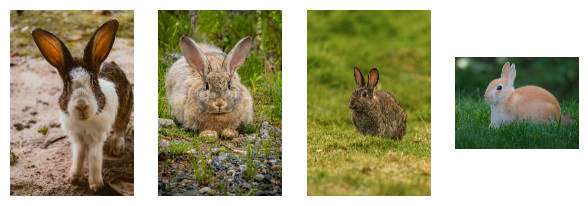

Cluster: 1
Number of images: 6


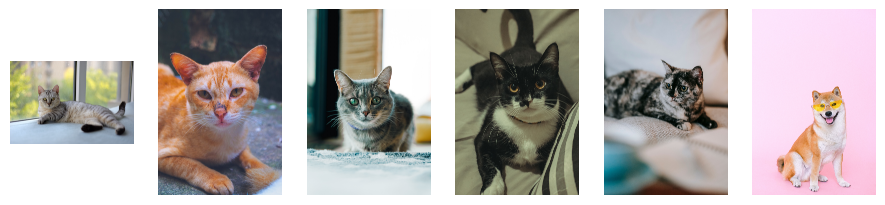

Cluster: 2
Number of images: 6


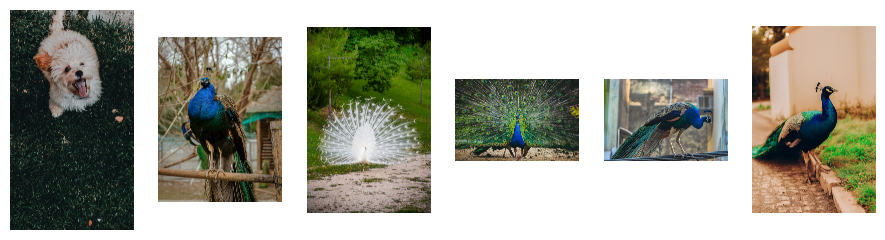

Cluster: 3
Number of images: 5


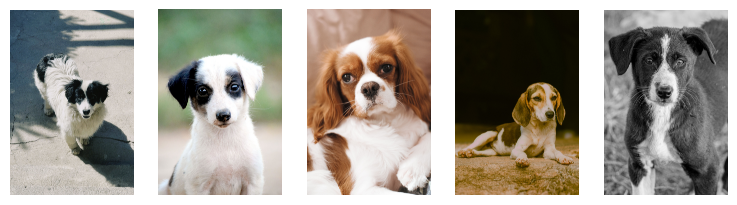

In [13]:
for cluster in range(4):

    indexes = np.where(labels == cluster)[0]

    print("Cluster:", cluster)
    print("Number of images:", len(indexes))

    plt.figure(figsize=(15, 4))

    for i, index in enumerate(indexes[:8]):

        img = Image.open(image_paths[index])

        plt.subplot(1, 8, i + 1)
        plt.imshow(img)
        plt.axis("off")

    plt.show()

In [14]:
from sklearn.metrics import silhouette_score

score = silhouette_score(features, labels)

print("Silhouette Score:", score)

Silhouette Score: 0.10654278


In [15]:
import shutil

output_folder = "Clustered_Images"

os.makedirs(output_folder, exist_ok=True)

for cluster in range(4):

    cluster_folder = os.path.join(
        output_folder,
        f"Cluster_{cluster}"
    )

    os.makedirs(cluster_folder, exist_ok=True)

    indexes = np.where(labels == cluster)[0]

    for index in indexes:

        source = image_paths[index]

        destination = os.path.join(
            cluster_folder,
            os.path.basename(source)
        )

        shutil.copy2(source, destination)

print("Images saved successfully!")

Images saved successfully!
